Spike counts before plasticity: <spikemonitor_1.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>


WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Plasticity step 0.0 ms
Plasticity step 1000.0 ms
Plasticity step 2000.0 ms
Plasticity step 3000.0 ms
Plasticity step 4000.0 ms
Plasticity step 5000.0 ms
Plasticity step 6000.0 ms
Plasticity step 7000.0 ms
Plasticity step 8000.0 ms
Plasticity step 9000.0 ms
Spike counts after run: <spikemonitor_1.count: array([1314,  245, 1314, 1314, 1314, 1314,  235,  231,  283, 1314, 1314,
        236, 1314,  150,  130, 1314, 1314,  179,  271,  173], dtype=int32)>
Number of synapses: 380


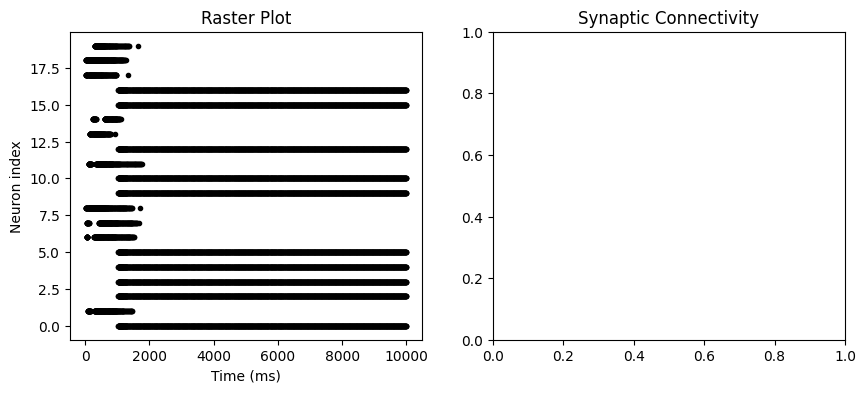

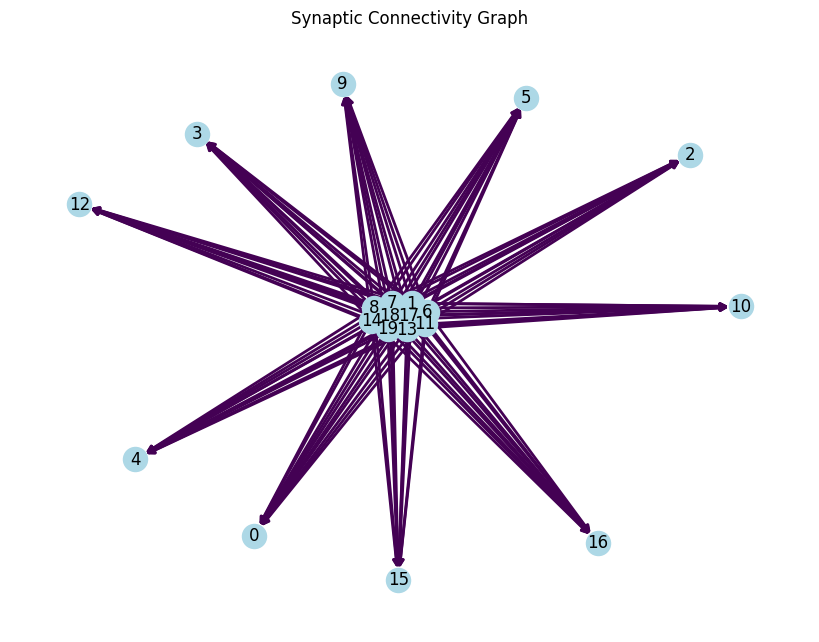

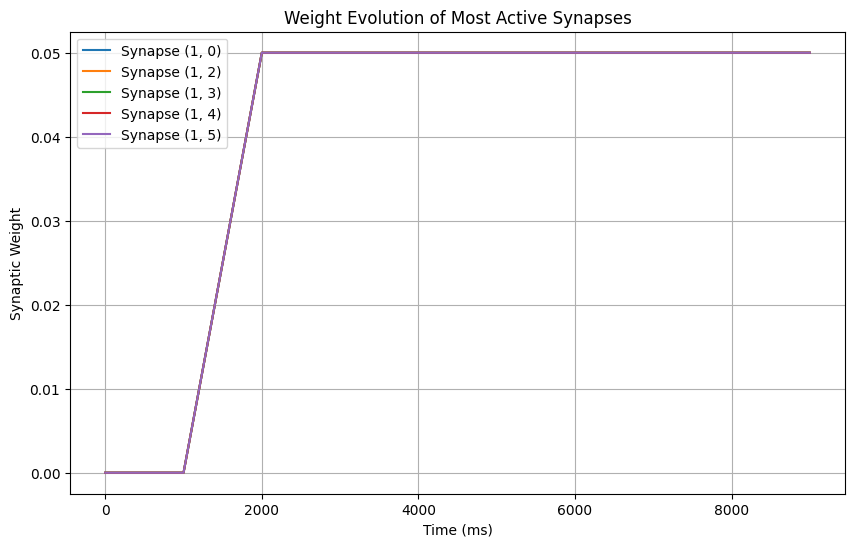

In [2]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
duration = 10*second
target_rate = 10*Hz
weight_trace = {}
times = []

# HH model equations
eqs = '''
dv/dt = (I_inj/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_inj = 0*nA

# Poisson input to 15 random neurons
stim_indices = np.random.choice(N, size=10, replace=False)
P_input = PoissonGroup(10, rates=10*Hz)
S_input = Synapses(P_input, neurons, on_pre='I_inj_post += 1.5*nA')
S_input.connect(i=range(10), j=stim_indices)

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_inj_post += w*nA')

S_rec.connect(condition='i != j')
S_rec.w[:] = 0.0  # initial weights

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 100 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    overactive = np.where(rates >= target_rate)[0]
    print("Plasticity step", defaultclock.t/ms, "ms")
    for u in underactive:
        for o in overactive:
            if o == u:
                continue  # skip self-connection
            S_rec.w[o, u] = clip(S_rec.w[o, u] + 0.05, 0, 1.0)

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)

print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")

# Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# Network graph
print(f"Number of synapses: {len(S_rec.i[:])}")

plt.subplot(122)
plt.title("Synaptic Connectivity")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.title("Synaptic Connectivity Graph")
    plt.show()

def find_most_active_synapses(weight_trace):
    # Calculate the change in weight for each synapse
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)  # max change
    
    # Sort synapses by the largest change in weight
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    
    # Select top N active synapses to monitor (e.g., top 5)
    top_synapses = [synapse for synapse, _ in most_active[:5]]
    
    return top_synapses

top_synapses = find_most_active_synapses(weight_trace)

# Plot their weight evolution
plt.figure(figsize=(10, 6))

for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')

plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()


In [3]:
stim_indices

array([ 7, 17,  8, 14,  1, 13,  6, 19, 11, 18])

WARNING    'w' is an internal variable of group 'synapses_5', but also exists in the run namespace with the value 0.10000000000000002. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Spike counts before plasticity: <spikemonitor.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>
Plasticity step 0.0 ms
Plasticity step 1000.0 ms
Plasticity step 2000.0 ms
Plasticity step 3000.0 ms
Plasticity step 4000.0 ms
Plasticity step 5000.0 ms
Plasticity step 6000.0 ms
Plasticity step 7000.0 ms
Plasticity step 8000.0 ms
Plasticity step 9000.0 ms
Spike counts after run: <spikemonitor.count: array([ 16, 208,  16, 167, 261,  16, 196, 262, 235, 270,  16, 318, 187,
       227, 273, 262, 268, 271,  16, 230], dtype=int32)>
Number of synapses: 380


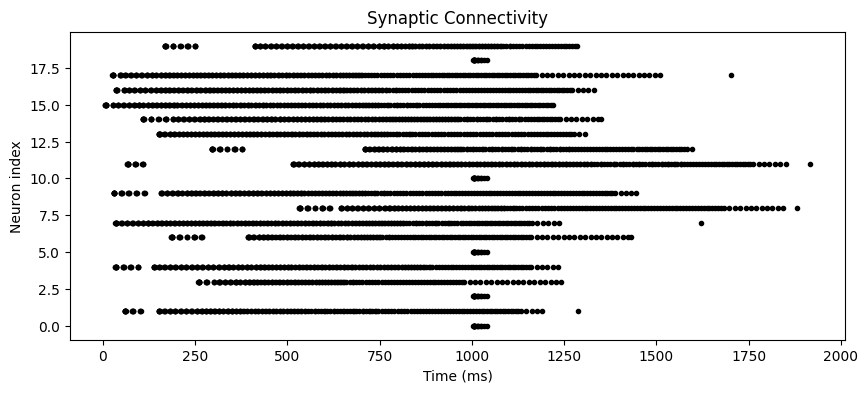

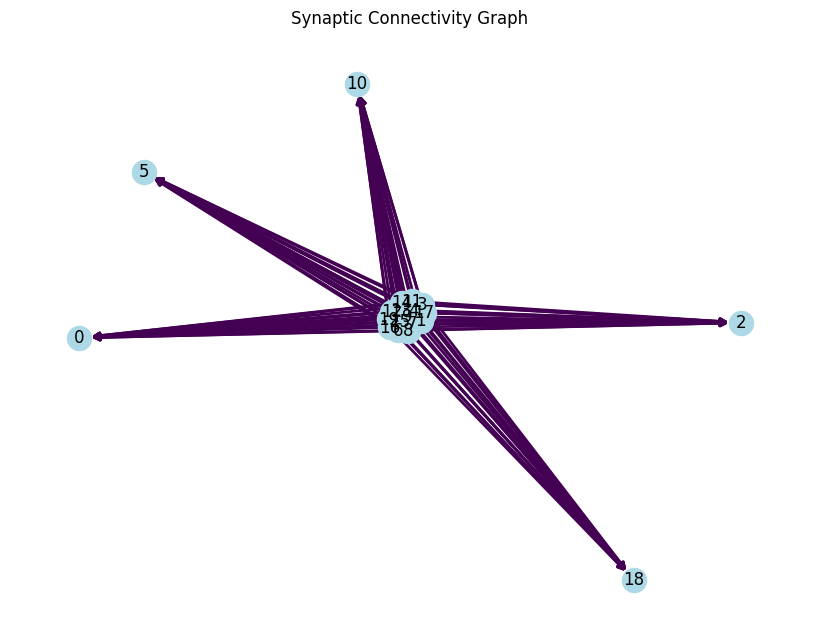

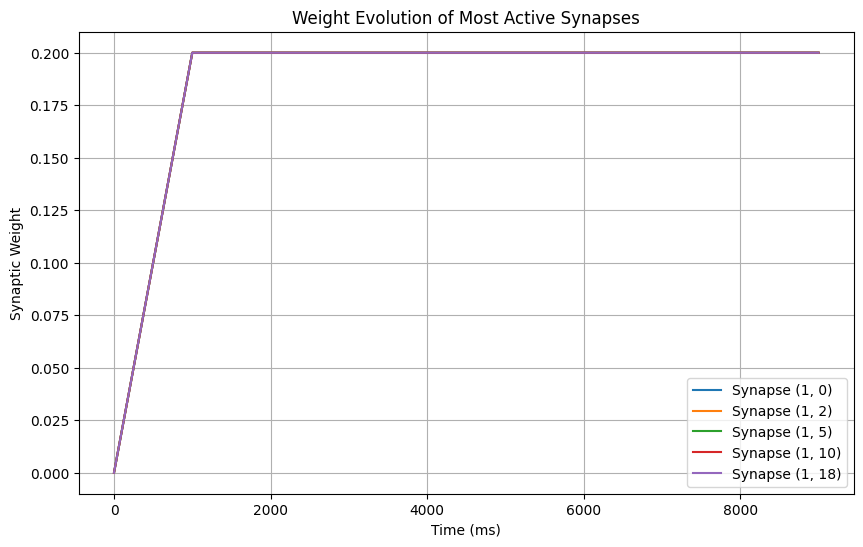

In [6]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
duration = 10*second
target_rate = 10*Hz
weight_trace = {}
times = []

# HH model equations
eqs = '''
dv/dt = (I_inj/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_inj = 0*nA

# Poisson input to 15 random neurons
stim_indices = np.random.choice(N, size=15, replace=False)
P_input = PoissonGroup(15, rates=10*Hz)
S_input = Synapses(P_input, neurons, on_pre='I_inj_post += 1.5*nA')
S_input.connect(i=range(15), j=stim_indices)

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_inj_post += w*nA')

S_rec.connect(condition='i != j')
S_rec.w[:] = 0.0  # initial weights

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 100 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    overactive = np.where(rates >= target_rate)[0]
    print("Plasticity step", defaultclock.t/ms, "ms")

    for u in underactive:
        for o in overactive:
            if o == u:
                continue
            S_rec.w[o, u] = clip(S_rec.w[o, u] + 0.05, 0, 1.0)

    # --- Synaptic normalization (preserve total output per neuron) ---
    for o in range(N):
        outgoing = S_rec.w[o, :]  # outgoing weights from neuron o
        total = sum(outgoing)
        if total > 0:
            S_rec.w[o, :] = outgoing / total  # normalize to total=1.0


@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)

print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")

# Raster plot
plt.figure(figsize=(10, 4))
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# Network graph
print(f"Number of synapses: {len(S_rec.i[:])}")

plt.title("Synaptic Connectivity")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.title("Synaptic Connectivity Graph")
    plt.show()

def find_most_active_synapses(weight_trace):
    # Calculate the change in weight for each synapse
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)  # max change
    
    # Sort synapses by the largest change in weight
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    
    # Select top N active synapses to monitor (e.g., top 5)
    top_synapses = [synapse for synapse, _ in most_active[:5]]
    
    return top_synapses

top_synapses = find_most_active_synapses(weight_trace)

# Plot their weight evolution
plt.figure(figsize=(10, 6))

for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')

plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()


In [1]:
!pip install brian2tools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 387.5/387.5 kB 6.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.6/67.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 10.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 10.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 9.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.6/400.6 kB 6.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.4/401.4 kB 7.9 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 521.2/521.2 kB 7.7 MB/s eta 0:00:00ta 0:00:01
